Shape of the dataset: (383, 17)


,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No



Target variable distribution:
Recurred
No     275
Yes    108
Name: count, dtype: int64


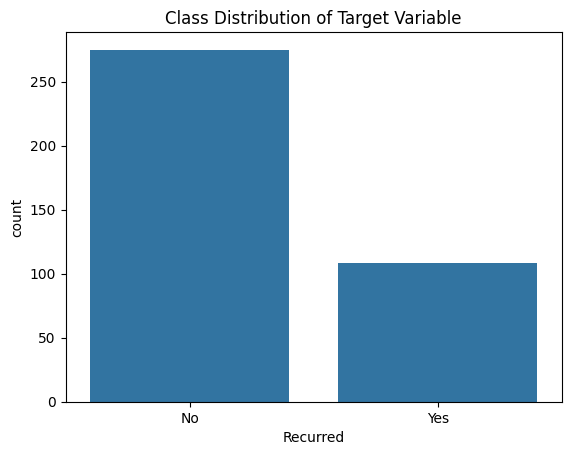

Missing values in each column:
Age                     0
Gender                  0
Smoking                 0
Hx Smoking              0
Hx Radiotherapy         0
Thyroid Function        0
Physical Examination    0
Adenopathy              0
Pathology               0
Focality                0
Risk                    0
T                       0
N                       0
M                       0
Stage                   0
Response                0
Recurred                0
dtype: int64
Training set size: 352
Validation set size: 88
Test set size: 110


/Users/agnellodcosta/Projects/pjas-thyroid/pjas-thyroid/lib/python3.12/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/Users/agnellodcosta/Projects/pjas-thyroid/pjas-thyroid/lib/python3.12/site-packages/sklearn/utils/_tags.py:354: FutureWarning: The SMOTE or classes from which it inherits use `_get_tags` and `_more_tags`. Please define the `__sklearn_tags__` method, or inherit from `sklearn.base.BaseEstimator` and/or other appropriate mixins such as `sklearn.base.TransformerMixin`, `sklearn.base.ClassifierMixin`, `sklearn.base.RegressorMixin`, and `sklearn.base.OutlierMixin`. From scikit-learn 1.7, not defining `__sklearn_tags__` will raise an error.
  warnings.warn(


Epoch [1/20], Train Loss: 0.6714, Val Loss: 0.6359
Epoch [2/20], Train Loss: 0.6027, Val Loss: 0.5680
Epoch [3/20], Train Loss: 0.5274, Val Loss: 0.4921
Epoch [4/20], Train Loss: 0.4548, Val Loss: 0.4152
Epoch [5/20], Train Loss: 0.3705, Val Loss: 0.3549
Epoch [6/20], Train Loss: 0.2983, Val Loss: 0.3208
Epoch [7/20], Train Loss: 0.2583, Val Loss: 0.3087
Epoch [8/20], Train Loss: 0.2293, Val Loss: 0.3106
Epoch [9/20], Train Loss: 0.2228, Val Loss: 0.3120
Epoch [10/20], Train Loss: 0.1992, Val Loss: 0.3163
Epoch [11/20], Train Loss: 0.2192, Val Loss: 0.3177
Epoch [12/20], Train Loss: 0.1844, Val Loss: 0.3186
Early stopping triggered.


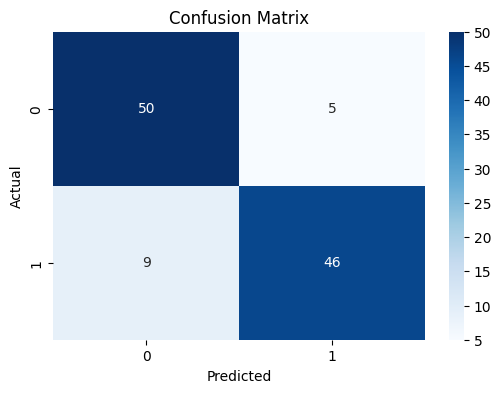

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.91      0.88        55
           1       0.90      0.84      0.87        55

    accuracy                           0.87       110
   macro avg       0.87      0.87      0.87       110
weighted avg       0.87      0.87      0.87       110



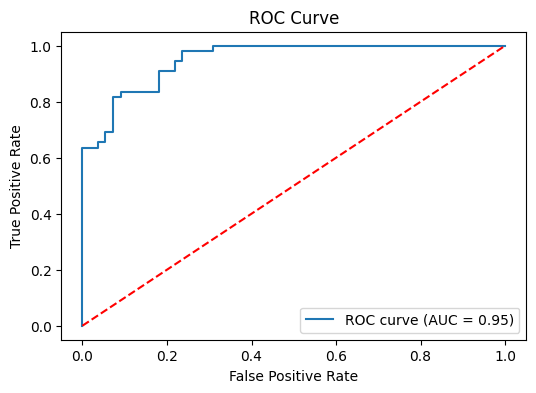

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from imblearn.over_sampling import SMOTE

# Set random seed for reproducibility
def set_seed(seed_value=42):
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)
    np.random.seed(seed_value)
    random.seed(seed_value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

# Load the dataset (replace with your actual path)
file_path = '../data/thyroid_diff.csv'
data = pd.read_csv(file_path)

# Basic overview of the dataset
print("Shape of the dataset:", data.shape)
display(data.head())

# Checking the target distribution
if 'Recurred' in data.columns:
    print("\nTarget variable distribution:")
    print(data['Recurred'].value_counts())
    sns.countplot(x='Recurred', data=data)
    plt.title('Class Distribution of Target Variable')
    plt.show()
else:
    raise ValueError("The dataset does not contain a 'Recurred' column.")

# Handle missing values
print("Missing values in each column:")
print(data.isnull().sum())
data = data.dropna()

# Encode categorical columns
categorical_columns = data.select_dtypes(include=['object']).columns
label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

# Separate features and target
X = data.drop('Recurred', axis=1)
y = data['Recurred']

# Address class imbalance with SMOTE
smote = SMOTE(random_state=42)
X, y = smote.fit_resample(X, y)

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split into training (64%), validation (16%), test (20%)
X_temp, X_test, y_temp, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2, random_state=42, stratify=y_temp)

print("Training set size:", X_train.shape[0])
print("Validation set size:", X_val.shape[0])
print("Test set size:", X_test.shape[0])

# Convert numpy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.long)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.long)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.long)

# Create DataLoaders
batch_size = 32
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_tensor, y_val_tensor), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_tensor, y_test_tensor), batch_size=batch_size, shuffle=False)

# Define the model
class ThyroidRecurrenceNet(nn.Module):
    def __init__(self, input_dim):
        super(ThyroidRecurrenceNet, self).__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.dropout1 = nn.Dropout(0.3)
        self.fc2 = nn.Linear(64, 32)
        self.dropout2 = nn.Dropout(0.3)
        self.fc3 = nn.Linear(32, 2)  # Binary classification

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.dropout1(x)
        x = torch.relu(self.fc2(x))
        x = self.dropout2(x)
        x = self.fc3(x)
        return x

model = ThyroidRecurrenceNet(X_train.shape[1])

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training and validation loop
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=20):
    best_val_loss = float('inf')
    patience = 5
    patience_counter = 0

    for epoch in range(num_epochs):
        # Training
        model.train()
        train_loss = 0.0
        for inputs, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        # Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, labels in val_loader:
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()

        train_loss = train_loss / len(train_loader)
        val_loss = val_loss / len(val_loader)

        print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save(model.state_dict(), 'best_model.pth')
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("Early stopping triggered.")
                break

    # Load the best model
    model.load_state_dict(torch.load('best_model.pth'))
    return model

model = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=20)

# Evaluation
def evaluate(model, data_loader):
    model.eval()
    preds = []
    trues = []
    with torch.no_grad():
        for inputs, labels in data_loader:
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            preds.extend(predicted.cpu().numpy())
            trues.extend(labels.cpu().numpy())
    return np.array(preds), np.array(trues)

preds, trues = evaluate(model, test_loader)

# Confusion matrix
cm = confusion_matrix(trues, preds)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Classification report
print("Classification Report:")
print(classification_report(trues, preds))

# ROC curve
probs = []
model.eval()
with torch.no_grad():
    for inputs, _ in test_loader:
        outputs = model(inputs)
        probs.append(torch.softmax(outputs, dim=1)[:, 1].cpu().numpy())
probs = np.concatenate(probs)
fpr, tpr, thresholds = roc_curve(trues, probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0,1],[0,1],'--', color='red')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title("ROC Curve")
plt.legend()
plt.show()
